# 12 · Does any graph carry information?
GraphSAGE and a residual GATv2 on five topologies (kNN, same DEM catchment, ridge-aware, same ward, random) vs a
graph-free MLP under identical spatial CV (`src/graph_topology_experiment.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
display(table("gt_topology_graph_stats.csv")); display(table("gt_topology_summary.csv")); table("gt_topology_paired.csv")

,topology,n_edges,mean_edge_length_m,median_edge_length_m,share_same_status,assortativity_kappa
0,knn,39823,261.9932,209.0810,0.6957,0.2233
1,catchment,39325,295.1801,215.4051,0.6990,0.2318
2,ridge,39823,286.4242,213.1053,0.6980,0.2291
3,ward,39823,336.0276,220.1743,0.6982,0.2297
4,random,39823,14112.6465,13066.5850,0.6096,0.0035


,model,topology,roc_auc,roc_auc_sd,pr_auc
0,GraphSAGE,catchment,0.6485,0.0587,0.4148
1,GraphSAGE,knn,0.6614,0.0539,0.4244
2,GraphSAGE,random,0.6689,0.0518,0.4312
3,GraphSAGE,ridge,0.6613,0.0565,0.4270
4,GraphSAGE,ward,0.6591,0.0551,0.4257
5,MLP,none,0.6657,0.0584,0.4282
6,ResGATv2,catchment,0.6633,0.0585,0.4234
7,ResGATv2,knn,0.6689,0.0591,0.4289
8,ResGATv2,random,0.6699,0.0549,0.4280
9,ResGATv2,ridge,0.6650,0.0580,0.4253


,model,topology,reference,mean_diff,ci_low,ci_high,p_corrected
0,GraphSAGE,knn,MLP,-0.0043,-0.0404,0.0318,0.8084
1,GraphSAGE,catchment,knn,-0.0129,-0.0487,0.0228,0.4619
2,GraphSAGE,catchment,MLP,-0.0172,-0.0596,0.0251,0.4093
3,GraphSAGE,ridge,knn,-0.0001,-0.0256,0.0254,0.9914
4,GraphSAGE,ridge,MLP,-0.0044,-0.0450,0.0361,0.8240
5,GraphSAGE,ward,knn,-0.0023,-0.0147,0.0101,0.7035
6,GraphSAGE,ward,MLP,-0.0066,-0.0383,0.0251,0.6715
7,GraphSAGE,random,knn,0.0075,-0.0237,0.0387,0.6247
8,GraphSAGE,random,MLP,0.0032,-0.0206,0.0270,0.7840
9,ResGATv2,knn,MLP,0.0032,-0.0281,0.0345,0.8336


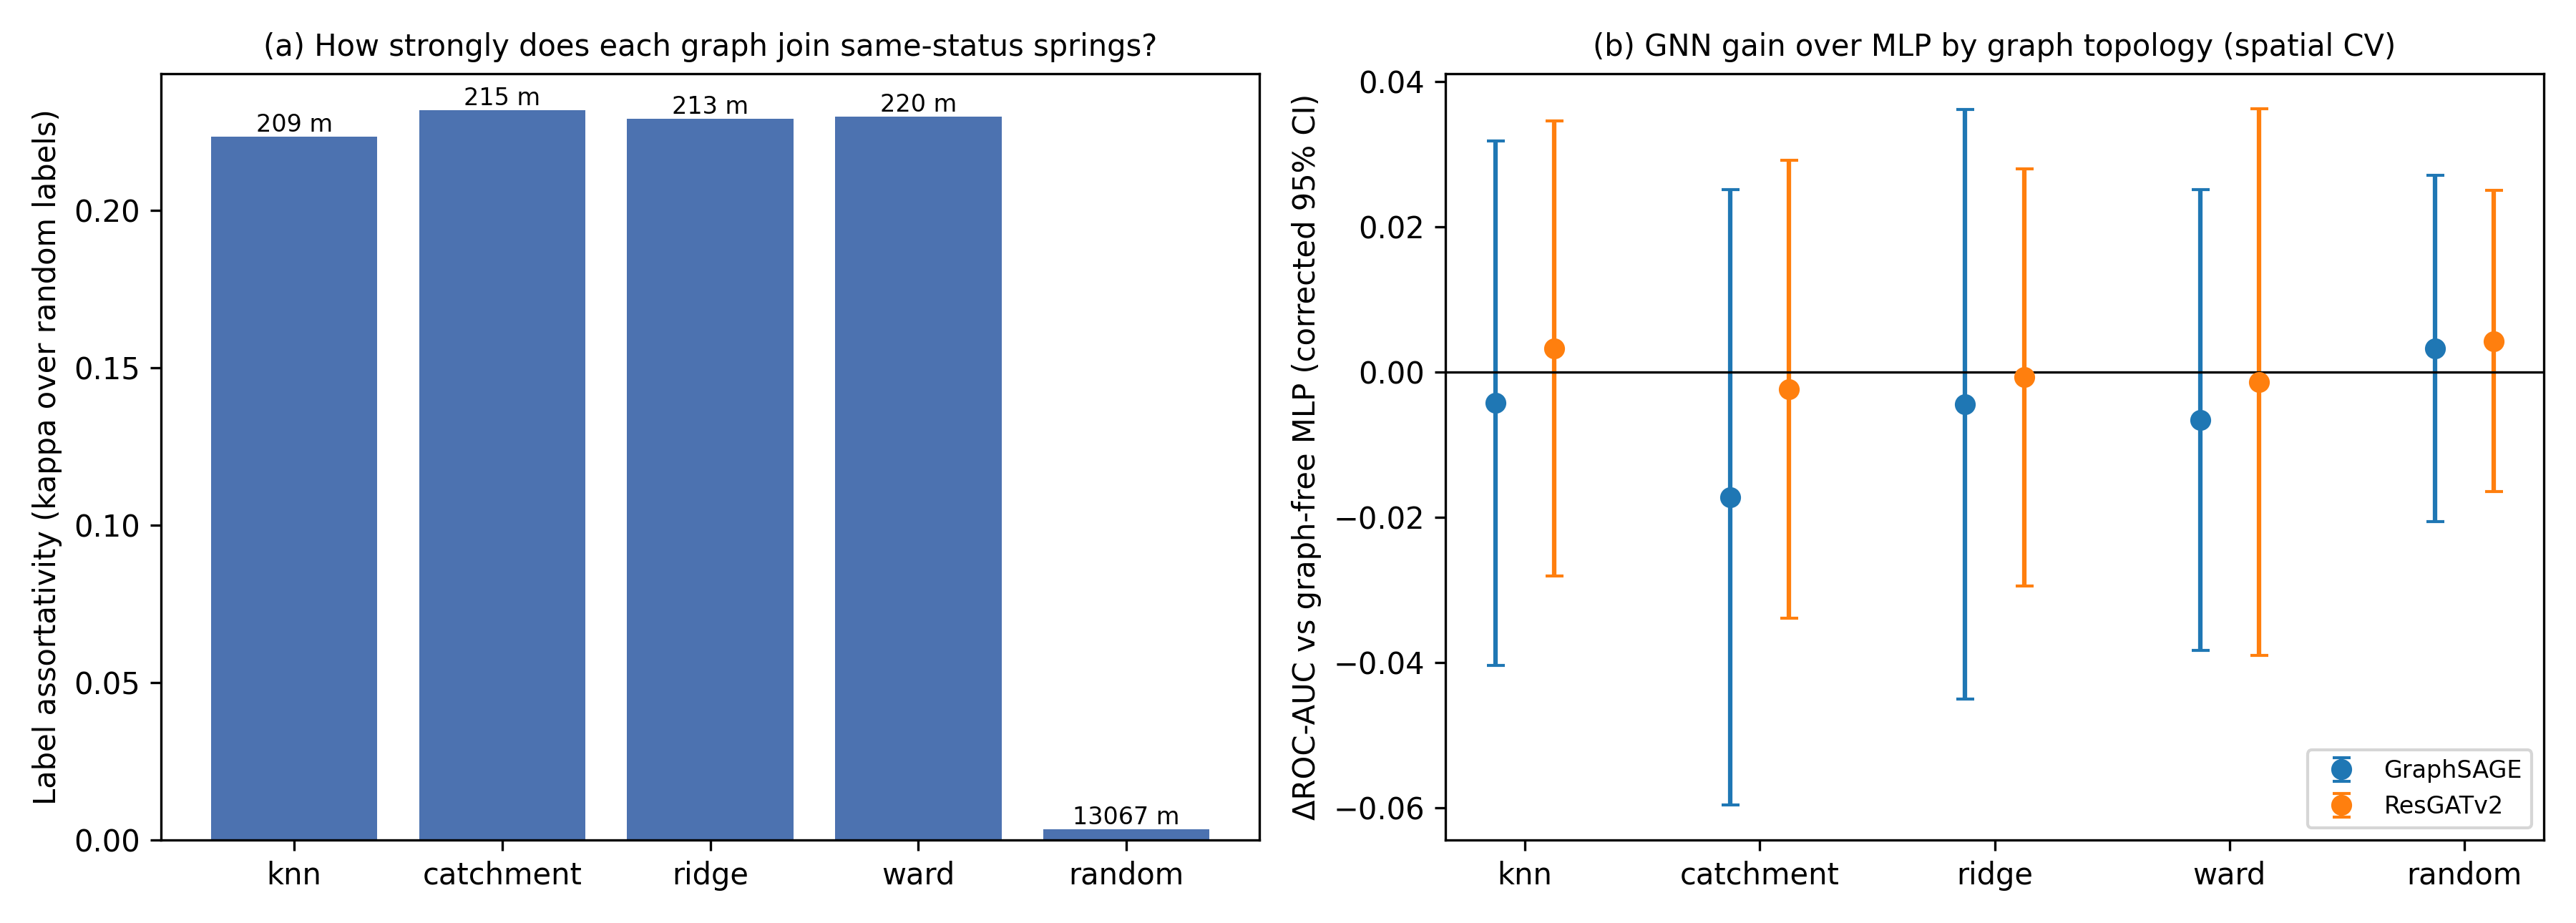

In [3]:
fig("gt_topology.png")